In [3]:
"""
Y-Net style dual-decoder segmentation script (Kvasir-SEG / Gastrointestinal imaging).
Complete script with Data Generator, Model, Metrics, Compilation, and Training Loop.
"""

import os
import numpy as np
import cv2
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras import backend as K
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau, EarlyStopping
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam

# ----------------------------------------------------------------------------
# 1. Image / Mask Preprocessing Utilities
# ----------------------------------------------------------------------------
def resize_image(image, size=(256, 256)):
    interpolation = cv2.INTER_AREA if len(image.shape) == 3 else cv2.INTER_NEAREST
    return cv2.resize(image, size, interpolation=interpolation)

def apply_clahe(image):
    lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    cl = clahe.apply(l)
    limg = cv2.merge((cl, a, b))
    return cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)

def apply_sharpening(image):
    kernel = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])
    return cv2.filter2D(image, -1, kernel)

def apply_gaussian_filter(image, kernel_size=(3, 3), sigma=0):
    return cv2.GaussianBlur(image, kernel_size, sigma)

def apply_erosion(mask, kernel_size=(3, 3)):
    kernel = np.ones(kernel_size, np.uint8)
    return cv2.erode(mask, kernel, iterations=1)

def apply_augmentations(image, mask_healthy, mask_polyp):
    if np.random.rand() > 0.5:
        image = cv2.flip(image, 1)
        mask_healthy = cv2.flip(mask_healthy, 1)
        mask_polyp = cv2.flip(mask_polyp, 1)
    if np.random.rand() > 0.5:
        image = cv2.flip(image, 0)
        mask_healthy = cv2.flip(mask_healthy, 0)
        mask_polyp = cv2.flip(mask_polyp, 0)
    return image, mask_healthy, mask_polyp

# ----------------------------------------------------------------------------
# 2. Data Generator
# ----------------------------------------------------------------------------
class KvasirDataGenerator(tf.keras.utils.Sequence):
    def __init__(self, img_paths, img_dir, healthy_dir, polyp_dir,
                 batch_size=4, img_size=(256, 256), is_train=True):
        self.img_paths = img_paths
        self.img_dir = img_dir
        self.healthy_dir = healthy_dir
        self.polyp_dir = polyp_dir
        self.batch_size = batch_size
        self.img_size = img_size
        self.is_train = is_train

    def __len__(self):
        return int(np.ceil(len(self.img_paths) / float(self.batch_size)))

    def __getitem__(self, idx):
        batch_paths = self.img_paths[idx * self.batch_size: (idx + 1) * self.batch_size]

        batch_x, batch_healthy, batch_polyp = [], [], []

        for img_path in batch_paths:
            filename = os.path.basename(img_path)
            healthy_path = os.path.join(self.healthy_dir, filename)
            polyp_path = os.path.join(self.polyp_dir, filename)

            image = cv2.imread(img_path)
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            healthy_mask = cv2.imread(healthy_path, cv2.IMREAD_GRAYSCALE)
            polyp_mask = cv2.imread(polyp_path, cv2.IMREAD_GRAYSCALE)

            image = resize_image(image, self.img_size)
            healthy_mask = resize_image(healthy_mask, self.img_size)
            polyp_mask = resize_image(polyp_mask, self.img_size)

            image = apply_clahe(image)
            image = apply_sharpening(image)
            image = apply_gaussian_filter(image)

            healthy_mask = apply_erosion(healthy_mask)
            polyp_mask = apply_erosion(polyp_mask)

            if self.is_train:
                image, healthy_mask, polyp_mask = apply_augmentations(image, healthy_mask, polyp_mask)

            image = image.astype(np.float32) / 255.0
            healthy_mask = (healthy_mask > 127).astype(np.float32)
            polyp_mask = (polyp_mask > 127).astype(np.float32)

            batch_x.append(image)
            batch_healthy.append(healthy_mask[..., np.newaxis])
            batch_polyp.append(polyp_mask[..., np.newaxis])

        return (
            np.array(batch_x),
            {
                "healthy_output": np.array(batch_healthy),
                "polyp_output": np.array(batch_polyp),
            },
        )

# ----------------------------------------------------------------------------
# 3. Attention & Model Blocks (With Regularization & Dropout)
# ----------------------------------------------------------------------------
def squeeze_and_excitation(input_tensor, ratio=16):
    filters = input_tensor.shape[-1]
    se = layers.GlobalAveragePooling2D()(input_tensor)
    se = layers.Reshape((1, 1, filters))(se)
    se = layers.Dense(filters // ratio, activation="relu", use_bias=False)(se)
    se = layers.Dense(filters, activation="sigmoid", use_bias=False)(se)
    return layers.Multiply()([input_tensor, se])

def cbam_block(input_tensor, ratio=16):
    filters = input_tensor.shape[-1]
    shared_dense_1 = layers.Dense(filters // ratio, activation="relu", use_bias=False)
    shared_dense_2 = layers.Dense(filters, use_bias=False)

    avg_pool = layers.GlobalAveragePooling2D()(input_tensor)
    avg_pool = layers.Reshape((1, 1, filters))(avg_pool)
    avg_out = shared_dense_2(shared_dense_1(avg_pool))

    max_pool = layers.GlobalMaxPooling2D()(input_tensor)
    max_pool = layers.Reshape((1, 1, filters))(max_pool)
    max_out = shared_dense_2(shared_dense_1(max_pool))

    channel_attention = layers.Activation("sigmoid")(layers.Add()([avg_out, max_out]))
    x = layers.Multiply()([input_tensor, channel_attention])

    avg_pool_sp = layers.Lambda(lambda z: tf.reduce_mean(z, axis=-1, keepdims=True))(x)
    max_pool_sp = layers.Lambda(lambda z: tf.reduce_max(z, axis=-1, keepdims=True))(x)
    concat = layers.Concatenate(axis=-1)([avg_pool_sp, max_pool_sp])

    spatial_attention = layers.Conv2D(1, kernel_size=7, padding="same", activation="sigmoid", use_bias=False)(concat)
    return layers.Multiply()([x, spatial_attention])

def se_encoder_block(inputs, filters, l2_weight=1e-4):
    x = layers.Conv2D(filters, 3, padding="same", kernel_regularizer=l2(l2_weight))(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(filters, 3, padding="same", kernel_regularizer=l2(l2_weight))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = squeeze_and_excitation(x)
    p = layers.MaxPooling2D((2, 2))(x)
    return x, p

def cbam_decoder_block(inputs, skip_features, filters, dropout_rate=0.2, l2_weight=1e-4):
    x = layers.Conv2DTranspose(filters, 2, strides=(2, 2), padding="same", kernel_regularizer=l2(l2_weight))(inputs)
    x = layers.Concatenate()([x, skip_features])
    x = layers.Conv2D(filters, 3, padding="same", kernel_regularizer=l2(l2_weight))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    
    if dropout_rate > 0:
        x = layers.SpatialDropout2D(dropout_rate)(x)

    x = layers.Conv2D(filters, 3, padding="same", kernel_regularizer=l2(l2_weight))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = cbam_block(x)
    return x

def build_dual_decoder_unet(input_shape=(256, 256, 3), l2_weight=1e-4):
    inputs = layers.Input(input_shape)

    s1, p1 = se_encoder_block(inputs, 64, l2_weight)
    s2, p2 = se_encoder_block(p1, 128, l2_weight)
    s3, p3 = se_encoder_block(p2, 256, l2_weight)
    s4, p4 = se_encoder_block(p3, 512, l2_weight)

    b1 = layers.Conv2D(1024, 3, padding="same", kernel_regularizer=l2(l2_weight))(p4)
    b1 = layers.BatchNormalization()(b1)
    b1 = layers.Activation("relu")(b1)
    b1 = layers.Conv2D(1024, 3, padding="same", kernel_regularizer=l2(l2_weight))(b1)
    b1 = layers.BatchNormalization()(b1)
    b1 = layers.Activation("relu")(b1)
    b1 = squeeze_and_excitation(b1)

    h1 = cbam_decoder_block(b1, s4, 512, dropout_rate=0.2, l2_weight=l2_weight)
    h2 = cbam_decoder_block(h1, s3, 256, dropout_rate=0.2, l2_weight=l2_weight)
    h3 = cbam_decoder_block(h2, s2, 128, dropout_rate=0.2, l2_weight=l2_weight)
    h4 = cbam_decoder_block(h3, s1, 64, dropout_rate=0.0, l2_weight=l2_weight) 
    healthy_output = layers.Conv2D(1, 1, padding="same", activation="sigmoid", name="healthy_output", kernel_regularizer=l2(l2_weight))(h4)

    d1 = cbam_decoder_block(b1, s4, 512, dropout_rate=0.2, l2_weight=l2_weight)
    d2 = cbam_decoder_block(d1, s3, 256, dropout_rate=0.2, l2_weight=l2_weight)
    d3 = cbam_decoder_block(d2, s2, 128, dropout_rate=0.2, l2_weight=l2_weight)
    d4 = cbam_decoder_block(d3, s1, 64, dropout_rate=0.0, l2_weight=l2_weight)
    polyp_output = layers.Conv2D(1, 1, padding="same", activation="sigmoid", name="polyp_output", kernel_regularizer=l2(l2_weight))(d4)

    return models.Model(inputs, {"healthy_output": healthy_output, "polyp_output": polyp_output}, name="Y_Net_Dual_Decoder_UNet")

# ----------------------------------------------------------------------------
# 4. Metrics & Losses
# ----------------------------------------------------------------------------
def dice_coef(y_true, y_pred, smooth=1e-5):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)

def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)

import os
import glob
from sklearn.model_selection import train_test_split

# ----------------------------------------------------------------------------
# 5. Training Execution Setup
# ----------------------------------------------------------------------------
if __name__ == "__main__":

    # 5.1 Define paths (আপনার দেওয়া পাথ অনুযায়ী)
    IMG_DIR = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/images"
    HEALTHY_DIR = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/healthy-masks"
    POLYP_DIR = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/masks"
    
    # মডেল সেভ করার পাথ
    MODEL_SAVE_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/conference/claude/best_tf_dual_decoder_unet_v1.0.3.keras"
    
    # মডেল সেভ করার ফোল্ডার তৈরি (যদি না থাকে)
    SAVE_DIR = os.path.dirname(MODEL_SAVE_PATH)
    os.makedirs(SAVE_DIR, exist_ok=True)

    # সব ইমেজের পাথ নিয়ে Train এবং Validation সেটে ভাগ করা (80% Train, 20% Val)
    all_img_paths = glob.glob(os.path.join(IMG_DIR, "*.jpg"))
    train_img_paths, val_img_paths = train_test_split(all_img_paths, test_size=0.2, random_state=42)

    BATCH_SIZE = 4
    IMG_SIZE = (256, 256)
    EPOCHS = 100

    # 5.2 Initialize Generators
    train_gen = KvasirDataGenerator(
        train_img_paths, IMG_DIR, HEALTHY_DIR, POLYP_DIR,
        batch_size=BATCH_SIZE, img_size=IMG_SIZE, is_train=True
    )
    
    val_gen = KvasirDataGenerator(
        val_img_paths, IMG_DIR, HEALTHY_DIR, POLYP_DIR,
        batch_size=BATCH_SIZE, img_size=IMG_SIZE, is_train=False
    )

    # 5.3 Build Model
    model = build_dual_decoder_unet(input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3))

    # 5.4 Compile Model
    model.compile(
        optimizer=Adam(learning_rate=1e-4),
        loss={
            "healthy_output": dice_loss, 
            "polyp_output": dice_loss
        },
        loss_weights={
            "healthy_output": 0.3, 
            "polyp_output": 0.7
        },
        metrics={
            "healthy_output": [dice_coef, 'accuracy'],
            "polyp_output": [dice_coef, 'accuracy']
        }
    )

    # 5.5 Callbacks Setup
    callbacks = [
        ModelCheckpoint(
            filepath=MODEL_SAVE_PATH, 
            monitor="val_loss", 
            save_best_only=True, 
            mode="min", 
            verbose=1
        ),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-6, verbose=1),
        EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True, verbose=1)
    ]

    # 5.6 Train Model
    print("Starting training...")
    history = model.fit(
        train_gen,
        validation_data=val_gen,
        epochs=EPOCHS,
        callbacks=callbacks
    )
    print("Training finished successfully!")

    # 5.7 Save Final Model (Optional)
    final_model_path = os.path.join(SAVE_DIR, "final_tf_dual_decoder_unet_v1.0.3.keras")
    model.save(final_model_path)
    
    print(f"✅ Best model saved at: {MODEL_SAVE_PATH}")
    print(f"✅ Final model saved at: {final_model_path}")

Starting training...
Epoch 1/100


I0000 00:00:1787248852.218462   75338 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_73781__.453
W0000 00:00:1787248866.150012   75338 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 4.16GiB (rounded to 4464083456)requested by op 
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.
I0000 00:00:1787248866.172053   75338 bfc_allocator.cc:1049] BFCAllocator dump for GPU_0_bfc
I0000 00:00:1787248866.172067   75338 bfc_allocator.cc:1056] Bin (256): 	Total Chunks: 214, Chunks in use: 214. 53.5KiB allocated for chunks. 53.5KiB in use in bin. 29.2KiB client-requested in use in bin.
I0000 00:00:1787248866.172077   75338 bfc_allocator.cc:1056] Bin (512): 	Total Chunks: 138, Chunks in use: 138. 69.5KiB allocated for chunks. 69.5KiB in use in bin. 65.1KiB client-requested in use in bi

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 269ms/step - healthy_output_accuracy: 0.7258 - healthy_output_dice_coef: 0.7141 - healthy_output_loss: 0.2859 - loss: 1.3265 - polyp_output_accuracy: 0.6194 - polyp_output_dice_coef: 0.2567 - polyp_output_loss: 0.7433

I0000 00:00:1787249123.112885   75336 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_78761__.99



Epoch 1: val_loss improved from None to 0.83420, saving model to /mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/conference/claude/best_tf_dual_decoder_unet_v1.0.3.keras

Epoch 1: finished saving model to /mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/conference/claude/best_tf_dual_decoder_unet_v1.0.3.keras
200/200 ━━━━━━━━━━━━━━━━━━━━ 330s 401ms/step - healthy_output_accuracy: 0.7598 - healthy_output_dice_coef: 0.7593 - healthy_output_loss: 0.2407 - loss: 1.0638 - polyp_output_accuracy: 0.6400 - polyp_output_dice_coef: 0.2874 - polyp_output_loss: 0.7126 - val_healthy_output_accuracy: 0.8326 - val_healthy_output_dice_coef: 0.7571 - val_healthy_output_loss: 0.2429 - val_loss: 0.8342 - val_polyp_output_accuracy: 0.8469 - val_polyp_output_dice_coef: 0.1928 - val_polyp_output_loss: 0.8072 - learning_rate: 1.0000e-04
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 265ms/step - healthy_output_accuracy: 0.8369 - healthy_output_dice_coef: 0.8502 - heal

Saved training curves to: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/conference/claude/best_tf_dual_decoder_unet_v1.0.3_curves.png


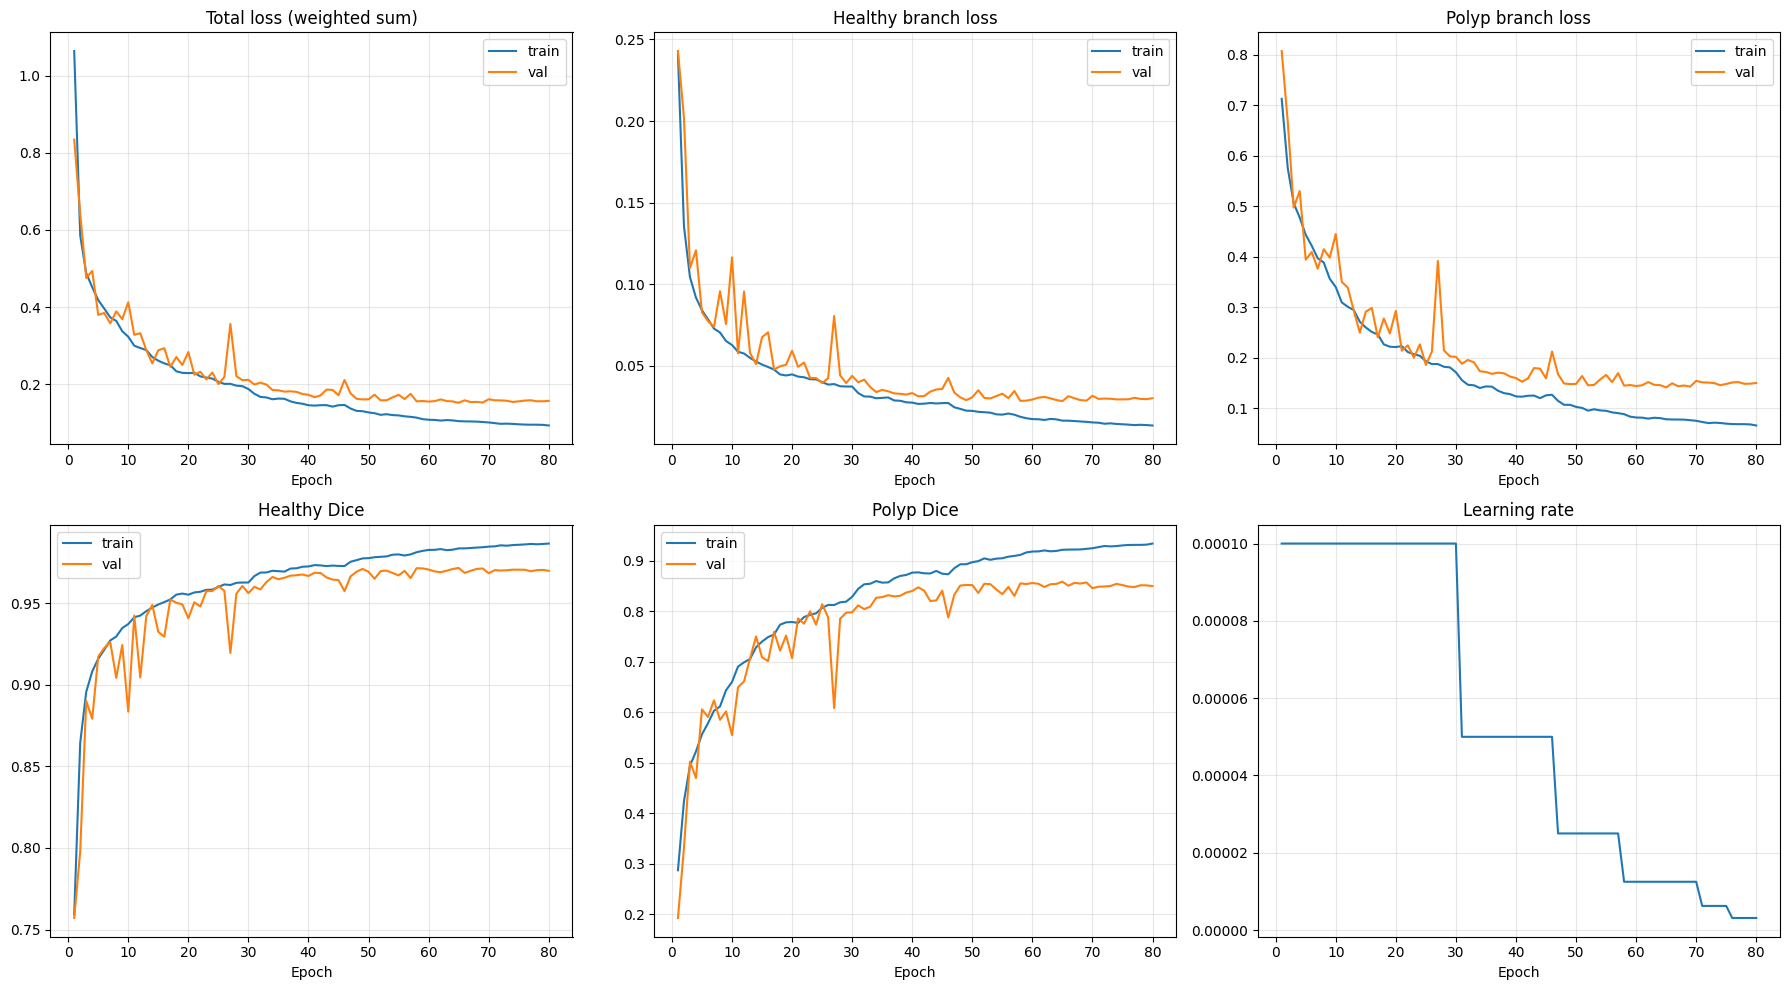


--- Training Complete. Evaluating on Test Set ---


In [9]:
import matplotlib.pyplot as plt
def plot_training_curves(hist, save_path=None):
    """hist: a dict like history.history (or one loaded back from pickle)."""
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))

    pairs = [
        ("loss", "val_loss", "Total loss (weighted sum)"),
        ("healthy_output_loss", "val_healthy_output_loss", "Healthy branch loss"),
        ("polyp_output_loss", "val_polyp_output_loss", "Polyp branch loss"),
        ("healthy_output_dice_coef", "val_healthy_output_dice_coef", "Healthy Dice"),
        ("polyp_output_dice_coef", "val_polyp_output_dice_coef", "Polyp Dice"),
    ]

    for ax, (train_key, val_key, title) in zip(axes.flat, pairs):
        if train_key not in hist:
            ax.axis("off")
            continue
        epochs_range = range(1, len(hist[train_key]) + 1)
        ax.plot(epochs_range, hist[train_key], label="train")
        if val_key in hist:
            ax.plot(epochs_range, hist[val_key], label="val")
        ax.set_title(title)
        ax.set_xlabel("Epoch")
        ax.legend()
        ax.grid(alpha=0.3)

    # last subplot: learning rate, if tracked
    ax = axes.flat[5]
    if "learning_rate" in hist:
        ax.plot(range(1, len(hist["learning_rate"]) + 1), hist["learning_rate"])
        ax.set_title("Learning rate")
        ax.set_xlabel("Epoch")
        ax.grid(alpha=0.3)
    else:
        ax.axis("off")

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
        print(f"Saved training curves to: {save_path}")
    plt.show()
MODEL_SAVE_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/conference/claude/best_tf_dual_decoder_unet_v1.0.3.keras"
CURVES_SAVE_PATH = MODEL_SAVE_PATH.replace(".keras", "_curves.png")
plot_training_curves(history.history, save_path=CURVES_SAVE_PATH)

# ----------------------------------------------------------------------------
# Evaluate
# ----------------------------------------------------------------------------
print("\n--- Training Complete. Evaluating on Test Set ---")
model.load_weights(MODEL_SAVE_PATH)
# return_dict=True gives correctly-labeled results directly -- avoids the
# earlier zip(model.metrics_names, test_metrics) mismatch bug in Keras 3
# multi-output models (metrics_names doesn't always expand cleanly).
#test_results = model.evaluate(test_gen, verbose=1, return_dict=True)
#print(test_results)


In [16]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import precision_score, recall_score, f1_score, jaccard_score, accuracy_score
from tensorflow.keras.models import load_model

# ---------------------------------------------------------
# কাস্টম ফাংশন
# ---------------------------------------------------------
def dice_coef(y_true, y_pred, smooth=1e-5):
    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(y_pred)
    intersection = tf.keras.backend.sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (tf.keras.backend.sum(y_true_f) + tf.keras.backend.sum(y_pred_f) + smooth)

def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)

# ---------------------------------------------------------
# মেট্রিক্স ক্যালকুলেট করার ফাংশন
# ---------------------------------------------------------
def evaluate_model_metrics(model, data_generator, dataset_name="Validation"):
    print(f"--- Evaluating {dataset_name} Data ---")
    
    all_healthy_true, all_healthy_pred = [], []
    all_polyp_true, all_polyp_pred = [], []
    
    # ডেটা জেনারেটর থেকে ব্যাচ অনুযায়ী প্রেডিকশন নেওয়া
    for i in range(len(data_generator)):
        x_batch, y_batch_dict = data_generator[i]
        
        # Ground Truth
        y_true_healthy = y_batch_dict['healthy_output']
        y_true_polyp = y_batch_dict['polyp_output']
        
        # Model Prediction
        preds = model.predict(x_batch, verbose=0)
        y_pred_healthy = preds['healthy_output']
        y_pred_polyp = preds['polyp_output']
        
        # Thresholding (০.৫ এর বেশি হলে ১, নাহলে ০)
        y_pred_healthy = (y_pred_healthy > 0.5).astype(np.float32)
        y_pred_polyp = (y_pred_polyp > 0.5).astype(np.float32)
        
        # ফ্ল্যাটেন করে লিস্টে যুক্ত করা (pixel-wise calculation এর জন্য)
        all_healthy_true.append(y_true_healthy.flatten())
        all_healthy_pred.append(y_pred_healthy.flatten())
        
        all_polyp_true.append(y_true_polyp.flatten())
        all_polyp_pred.append(y_pred_polyp.flatten())

    # কনক্যাটিনেট করা
    healthy_true = np.concatenate(all_healthy_true)
    healthy_pred = np.concatenate(all_healthy_pred)
    
    polyp_true = np.concatenate(all_polyp_true)
    polyp_pred = np.concatenate(all_polyp_pred)
    
    # ---------------------------------------------------------
    # মেট্রিক্স প্রিন্ট করা
    # ---------------------------------------------------------
    def print_metrics(y_true, y_pred, class_name):
        # Accuracy
        accuracy = accuracy_score(y_true, y_pred)
        
        # Dice and F1-Score (They are mathematically identical in this context)
        dice = f1_score(y_true, y_pred)
        f1 = dice 
        
        # IoU (Jaccard index for the positive class)
        iou = jaccard_score(y_true, y_pred)
        
        # Mean IoU (Macro average of background and positive class)
        miou = jaccard_score(y_true, y_pred, average='macro')
        
        # Precision and Recall
        precision = precision_score(y_true, y_pred, zero_division=0)
        recall = recall_score(y_true, y_pred, zero_division=0)
        
        print(f"[{class_name} Class Metrics]")
        print(f"  Accuracy  : {accuracy:.4f}")
        print(f"  Dice      : {dice:.4f}")
        print(f"  F1-Score  : {f1:.4f}")
        print(f"  IoU       : {iou:.4f}")
        print(f"  mIoU      : {miou:.4f}")
        print(f"  Precision : {precision:.4f}")
        print(f"  Recall    : {recall:.4f}\n")

    print_metrics(healthy_true, healthy_pred, "HEALTHY")
    print_metrics(polyp_true, polyp_pred, "POLYP")
    print("-" * 40)

# ---------------------------------------------------------
# এক্সিকিউশন
# ---------------------------------------------------------
if __name__ == "__main__":
    # মডেল পাথ
    MODEL_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/conference/claude/best_tf_dual_decoder_unet_v1.0.3.keras"
    
    print("Building model architecture...")
    # ১. প্রথমে আপনার ফাংশন কল করে ফাঁকা মডেল তৈরি করুন (যেহেতু এই ফাংশনগুলো আপনার স্ক্রিপ্টেই আছে)
    IMG_SIZE = (256, 256)
    model = build_dual_decoder_unet(input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
    
    print("Loading weights into the model...")
    # ২. এরপর সেভ করা .keras ফাইল থেকে শুধুমাত্র ওয়েটগুলো লোড করুন
    model.load_weights(MODEL_PATH)
    print("Weights loaded successfully!")
    
    # ৩. এবার জেনারেটর দিয়ে ইভ্যালুয়েট করুন
    # evaluate_model_metrics(model, train_gen, dataset_name="Train")
    evaluate_model_metrics(model, val_gen, dataset_name="Validation")

Building model architecture...
Loading weights into the model...
Weights loaded successfully!
--- Evaluating Validation Data ---


I0000 00:00:1787272108.766081   75335 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_327787__.46


[HEALTHY Class Metrics]
  Accuracy  : 0.9549
  Dice      : 0.9732
  F1-Score  : 0.9732
  IoU       : 0.9477
  mIoU      : 0.8504
  Precision : 0.9646
  Recall    : 0.9819

[POLYP Class Metrics]
  Accuracy  : 0.9580
  Dice      : 0.8559
  F1-Score  : 0.8559
  IoU       : 0.7481
  mIoU      : 0.8501
  Precision : 0.9027
  Recall    : 0.8137

----------------------------------------


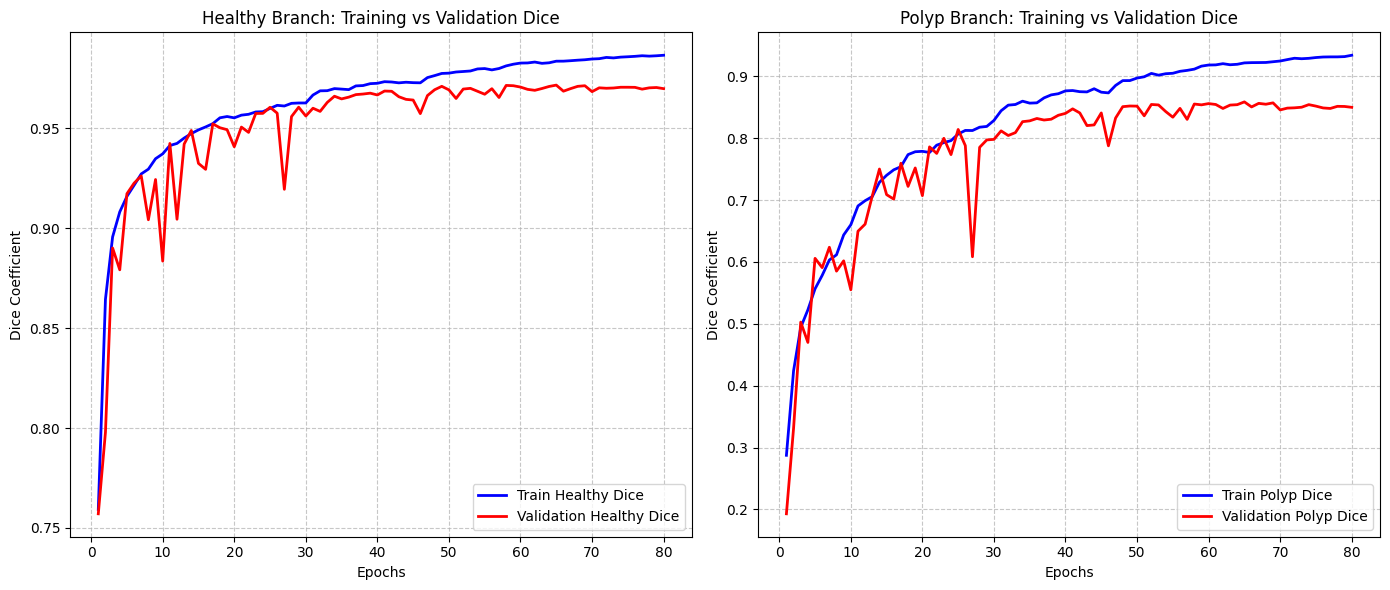

In [11]:
import matplotlib.pyplot as plt

def plot_dice_history(history):
    """
    মাল্টি-আউটপুট (Healthy এবং Polyp) মডেলের ডাইস স্কোরের গ্রাফ প্লট করার ফাংশন।
    """
    # Keras-এর history ডিকশনারি থেকে ডাইস স্কোরগুলো এক্সট্র্যাক্ট করা
    train_healthy_dice = history.history['healthy_output_dice_coef']
    val_healthy_dice = history.history['val_healthy_output_dice_coef']
    
    train_polyp_dice = history.history['polyp_output_dice_coef']
    val_polyp_dice = history.history['val_polyp_output_dice_coef']
    
    epochs = range(1, len(train_healthy_dice) + 1)
    
    # গ্রাফের সাইজ নির্ধারণ
    plt.figure(figsize=(14, 6))
    
    # ---------------------------------------------------------
    # ১. Healthy Class Dice Plot
    # ---------------------------------------------------------
    plt.subplot(1, 2, 1)
    plt.plot(epochs, train_healthy_dice, 'b-', label='Train Healthy Dice', linewidth=2)
    plt.plot(epochs, val_healthy_dice, 'r-', label='Validation Healthy Dice', linewidth=2)
    plt.title('Healthy Branch: Training vs Validation Dice')
    plt.xlabel('Epochs')
    plt.ylabel('Dice Coefficient')
    plt.legend(loc='lower right')
    plt.grid(True, linestyle='--', alpha=0.7)
    
    # ---------------------------------------------------------
    # ২. Polyp Class Dice Plot
    # ---------------------------------------------------------
    plt.subplot(1, 2, 2)
    plt.plot(epochs, train_polyp_dice, 'b-', label='Train Polyp Dice', linewidth=2)
    plt.plot(epochs, val_polyp_dice, 'r-', label='Validation Polyp Dice', linewidth=2)
    plt.title('Polyp Branch: Training vs Validation Dice')
    plt.xlabel('Epochs')
    plt.ylabel('Dice Coefficient')
    plt.legend(loc='lower right')
    plt.grid(True, linestyle='--', alpha=0.7)
    
    # গ্রাফ লেআউট ঠিক করা এবং প্রদর্শন করা
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# এক্সিকিউশন
# ---------------------------------------------------------
# model.fit() রান করার পর যে 'history' অবজেক্টটি তৈরি হয়, সেটি এই ফাংশনে পাস করুন
plot_dice_history(history)

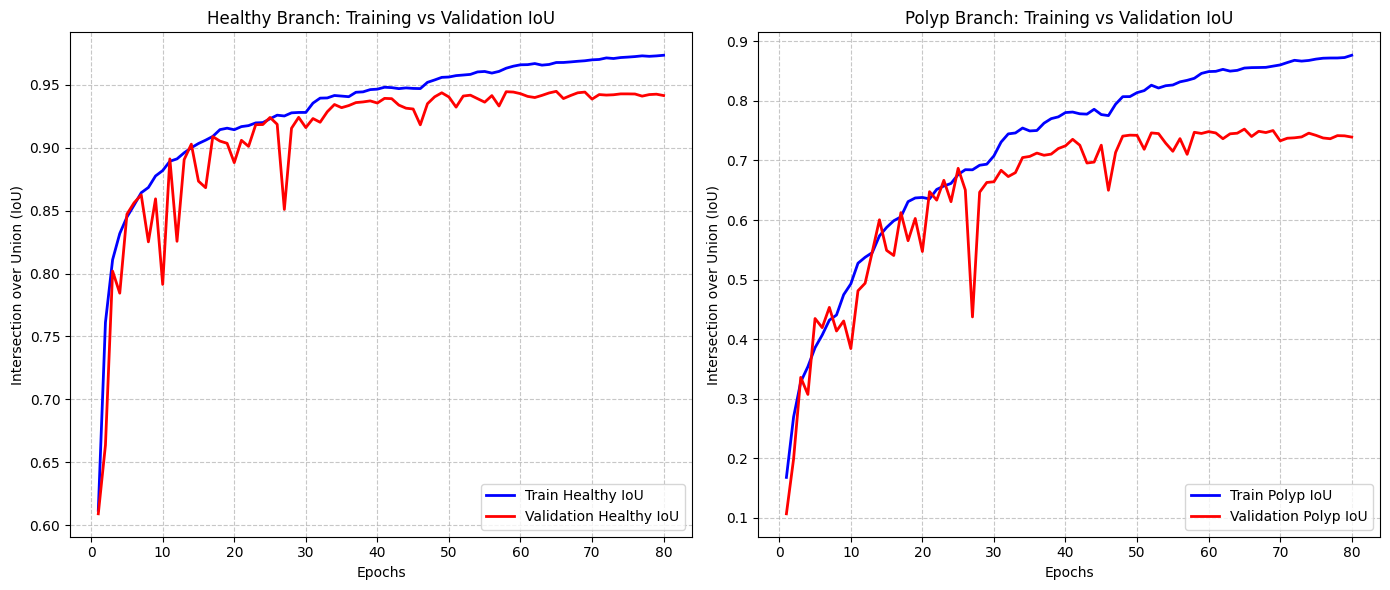

In [12]:
import matplotlib.pyplot as plt
import numpy as np

def plot_iou_history(history):
    """
    Dice স্কোর থেকে গাণিতিকভাবে IoU বের করে Healthy এবং Polyp ব্রাঞ্চের গ্রাফ প্লট করার ফাংশন।
    """
    # Keras-এর history ডিকশনারি থেকে ডাইস স্কোরগুলো এক্সট্র্যাক্ট করা
    # numpy array তে রূপান্তর করা হচ্ছে যাতে সহজে গাণিতিক সূত্র প্রয়োগ করা যায়
    train_healthy_dice = np.array(history.history['healthy_output_dice_coef'])
    val_healthy_dice = np.array(history.history['val_healthy_output_dice_coef'])
    
    train_polyp_dice = np.array(history.history['polyp_output_dice_coef'])
    val_polyp_dice = np.array(history.history['val_polyp_output_dice_coef'])
    
    # Dice থেকে IoU ক্যালকুলেশন: IoU = Dice / (2 - Dice)
    train_healthy_iou = train_healthy_dice / (2.0 - train_healthy_dice)
    val_healthy_iou = val_healthy_dice / (2.0 - val_healthy_dice)
    
    train_polyp_iou = train_polyp_dice / (2.0 - train_polyp_dice)
    val_polyp_iou = val_polyp_dice / (2.0 - val_polyp_dice)
    
    epochs = range(1, len(train_healthy_dice) + 1)
    
    # গ্রাফের সাইজ নির্ধারণ
    plt.figure(figsize=(14, 6))
    
    # ---------------------------------------------------------
    # ১. Healthy Class IoU Plot
    # ---------------------------------------------------------
    plt.subplot(1, 2, 1)
    plt.plot(epochs, train_healthy_iou, 'b-', label='Train Healthy IoU', linewidth=2)
    plt.plot(epochs, val_healthy_iou, 'r-', label='Validation Healthy IoU', linewidth=2)
    plt.title('Healthy Branch: Training vs Validation IoU')
    plt.xlabel('Epochs')
    plt.ylabel('Intersection over Union (IoU)')
    plt.legend(loc='lower right')
    plt.grid(True, linestyle='--', alpha=0.7)
    
    # ---------------------------------------------------------
    # ২. Polyp Class IoU Plot
    # ---------------------------------------------------------
    plt.subplot(1, 2, 2)
    plt.plot(epochs, train_polyp_iou, 'b-', label='Train Polyp IoU', linewidth=2)
    plt.plot(epochs, val_polyp_iou, 'r-', label='Validation Polyp IoU', linewidth=2)
    plt.title('Polyp Branch: Training vs Validation IoU')
    plt.xlabel('Epochs')
    plt.ylabel('Intersection over Union (IoU)')
    plt.legend(loc='lower right')
    plt.grid(True, linestyle='--', alpha=0.7)
    
    # গ্রাফ লেআউট ঠিক করা এবং প্রদর্শন করা
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# এক্সিকিউশন
# ---------------------------------------------------------
# model.fit() থেকে পাওয়া 'history' অবজেক্টটি এই ফাংশনে পাস করুন
plot_iou_history(history)

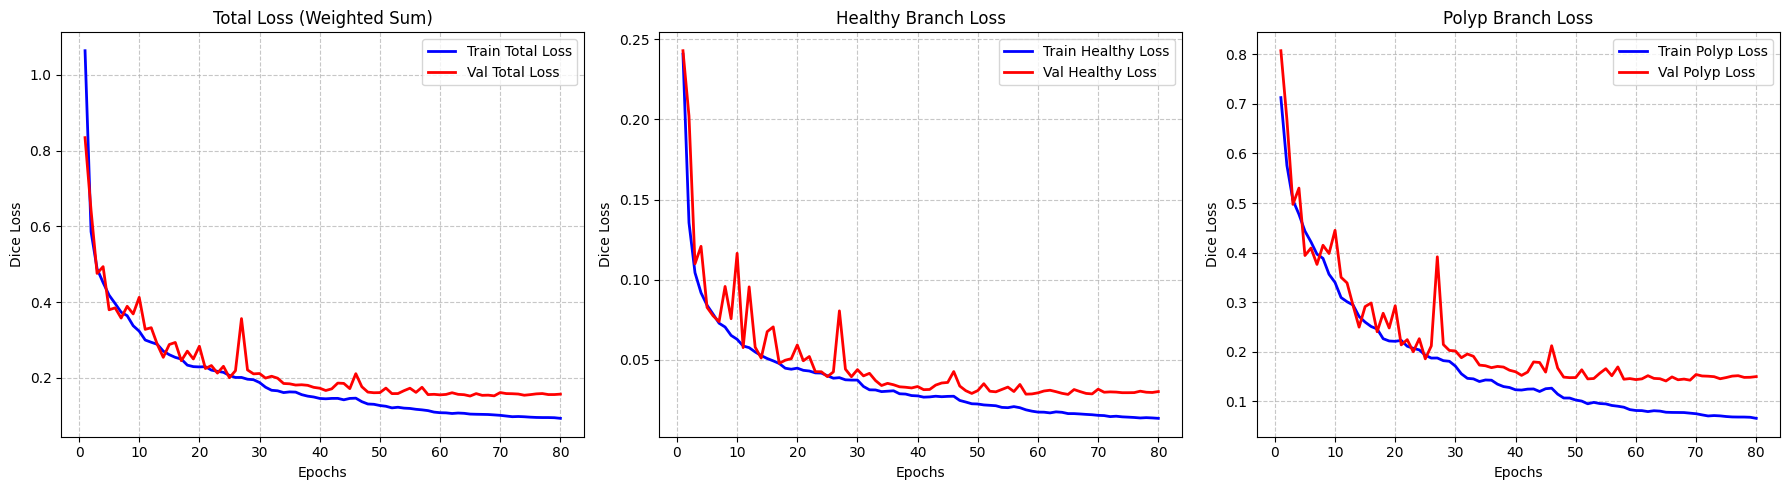

In [15]:
import matplotlib.pyplot as plt

def plot_dice_loss_history(history):
    """
    মাল্টি-আউটপুট মডেলের Dice Loss (Total, Healthy, Polyp) গ্রাফ প্লট করার ফাংশন।
    """
    # Keras-এর history ডিকশনারি থেকে Loss ভ্যালুগুলো এক্সট্র্যাক্ট করা
    train_loss = history.history['loss']
    val_loss = history.history['val_loss']
    
    train_healthy_loss = history.history['healthy_output_loss']
    val_healthy_loss = history.history['val_healthy_output_loss']
    
    train_polyp_loss = history.history['polyp_output_loss']
    val_polyp_loss = history.history['val_polyp_output_loss']
    
    epochs = range(1, len(train_loss) + 1)
    
    # গ্রাফের সাইজ নির্ধারণ (৩টি সাবপ্লট পাশাপাশি)
    plt.figure(figsize=(18, 5))
    
    # ---------------------------------------------------------
    # ১. Total Loss (Weighted Sum) Plot
    # ---------------------------------------------------------
    plt.subplot(1, 3, 1)
    plt.plot(epochs, train_loss, 'b-', label='Train Total Loss', linewidth=2)
    plt.plot(epochs, val_loss, 'r-', label='Val Total Loss', linewidth=2)
    plt.title('Total Loss (Weighted Sum)')
    plt.xlabel('Epochs')
    plt.ylabel('Dice Loss')
    plt.legend(loc='upper right')
    plt.grid(True, linestyle='--', alpha=0.7)
    
    # ---------------------------------------------------------
    # ২. Healthy Branch Dice Loss Plot
    # ---------------------------------------------------------
    plt.subplot(1, 3, 2)
    plt.plot(epochs, train_healthy_loss, 'b-', label='Train Healthy Loss', linewidth=2)
    plt.plot(epochs, val_healthy_loss, 'r-', label='Val Healthy Loss', linewidth=2)
    plt.title('Healthy Branch Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Dice Loss')
    plt.legend(loc='upper right')
    plt.grid(True, linestyle='--', alpha=0.7)
    
    # ---------------------------------------------------------
    # ৩. Polyp Branch Dice Loss Plot
    # ---------------------------------------------------------
    plt.subplot(1, 3, 3)
    plt.plot(epochs, train_polyp_loss, 'b-', label='Train Polyp Loss', linewidth=2)
    plt.plot(epochs, val_polyp_loss, 'r-', label='Val Polyp Loss', linewidth=2)
    plt.title('Polyp Branch Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Dice Loss')
    plt.legend(loc='upper right')
    plt.grid(True, linestyle='--', alpha=0.7)
    
    # গ্রাফ লেআউট ঠিক করা এবং প্রদর্শন করা
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# এক্সিকিউশন
# ---------------------------------------------------------
# model.fit() রান করার পর যে 'history' অবজেক্টটি তৈরি হয়, সেটি এই ফাংশনে পাস করুন
plot_dice_loss_history(history)

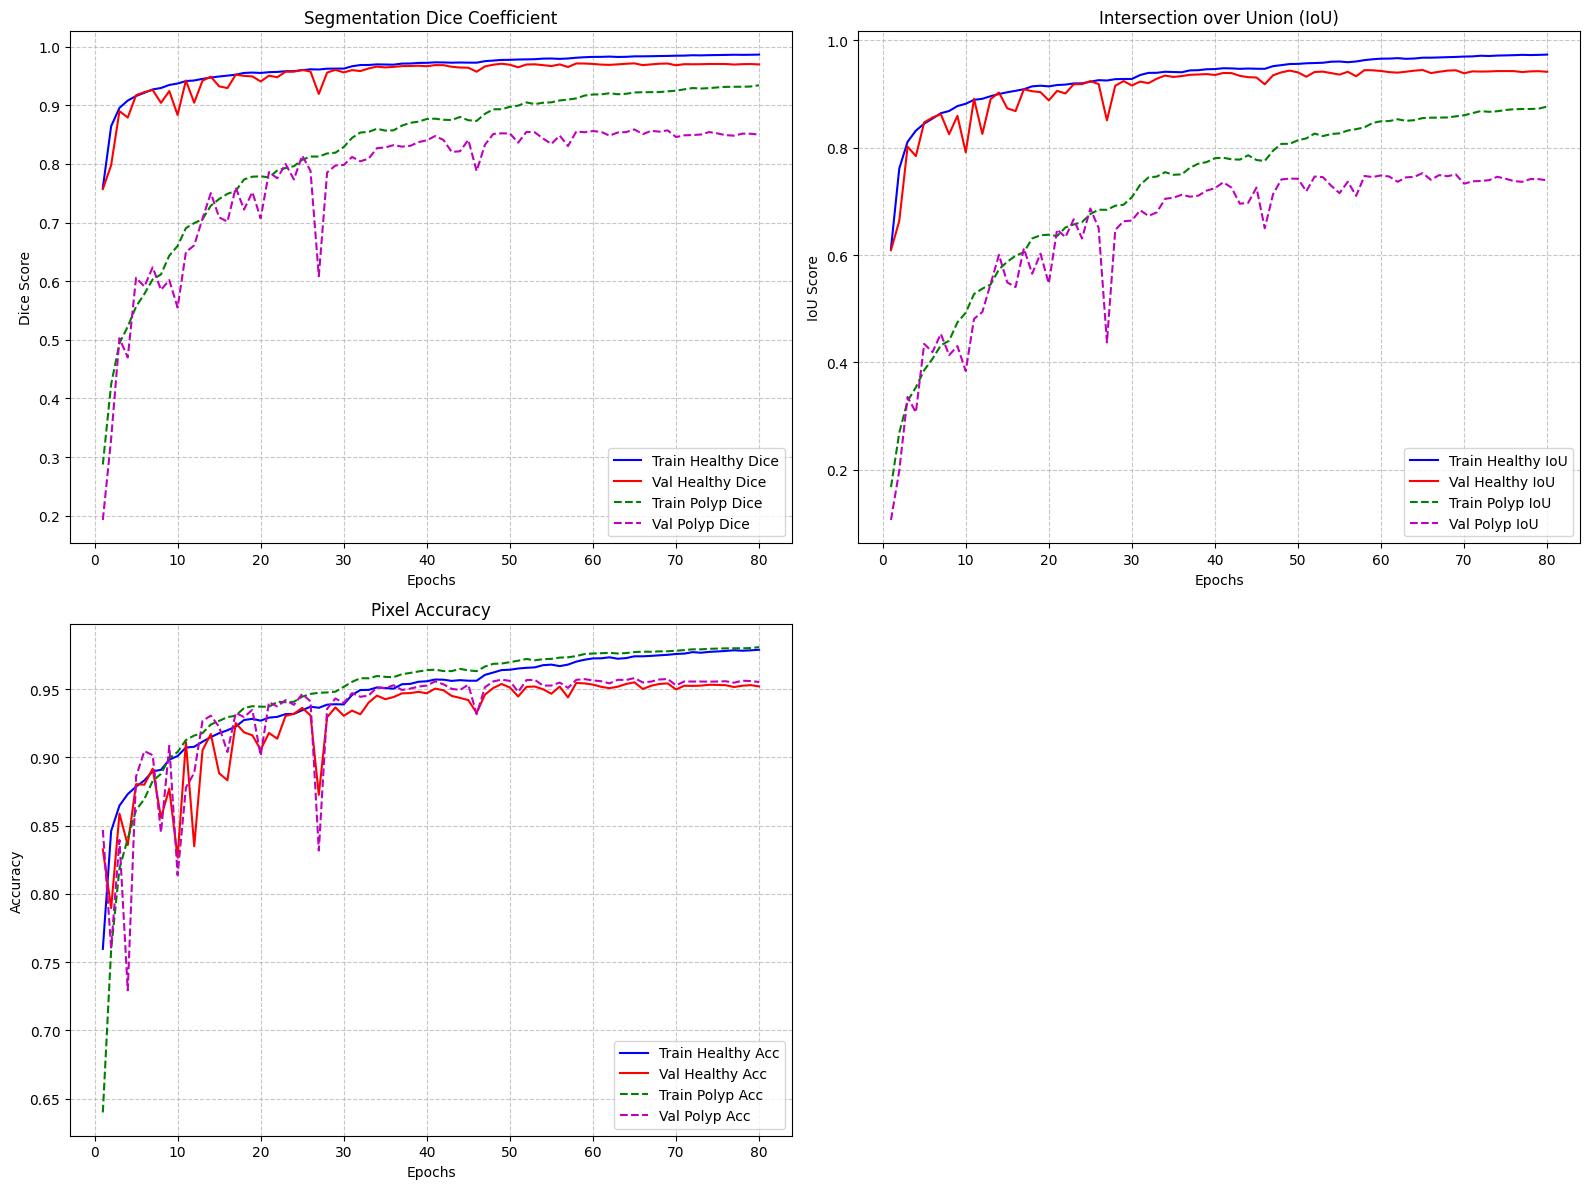

In [18]:
import matplotlib.pyplot as plt
import numpy as np

def plot_all_metrics_history(history):
    """
    টোটাল ট্রেইনিং হিস্ট্রি থেকে Accuracy, Dice, এবং IoU এর গ্রাফ প্লট করার ফাংশন।
    """
    epochs = range(1, len(history.history['loss']) + 1)
    
    # ১. ডাটা এক্সট্রাক্ট করা (Healthy এবং Polyp উভয় ব্রাঞ্চের জন্য)
    # Dice Scores
    train_h_dice = np.array(history.history['healthy_output_dice_coef'])
    val_h_dice = np.array(history.history['val_healthy_output_dice_coef'])
    train_p_dice = np.array(history.history['polyp_output_dice_coef'])
    val_p_dice = np.array(history.history['val_polyp_output_dice_coef'])
    
    # Accuracies (যদি ট্রেইনিংয়ে 'accuracy' মেট্রিক দেওয়া থাকে)
    has_acc = 'healthy_output_accuracy' in history.history
    if has_acc:
        train_h_acc = history.history['healthy_output_accuracy']
        val_h_acc = history.history['val_healthy_output_accuracy']
        train_p_acc = history.history['polyp_output_accuracy']
        val_p_acc = history.history['val_polyp_output_accuracy']
    
    # Dice থেকে IoU ক্যালকুলেশন: IoU = Dice / (2 - Dice)
    train_h_iou = train_h_dice / (2.0 - train_h_dice)
    val_h_iou = val_h_dice / (2.0 - val_h_dice)
    train_p_iou = train_p_dice / (2.0 - train_p_dice)
    val_p_iou = val_p_dice / (2.0 - val_p_dice)
    
    # গ্রাফ উইন্ডো সেটআপ (২ সারি, ২ কলাম)
    plt.figure(figsize=(16, 12))
    
    # ---------------------------------------------------------
    # সাবপ্লট ১: Dice Coefficient (Healthy & Polyp)
    # ---------------------------------------------------------
    plt.subplot(2, 2, 1)
    plt.plot(epochs, train_h_dice, 'b-', label='Train Healthy Dice', linewidth=1.5)
    plt.plot(epochs, val_h_dice, 'r-', label='Val Healthy Dice', linewidth=1.5)
    plt.plot(epochs, train_p_dice, 'g--', label='Train Polyp Dice', linewidth=1.5)
    plt.plot(epochs, val_p_dice, 'm--', label='Val Polyp Dice', linewidth=1.5)
    plt.title('Segmentation Dice Coefficient')
    plt.xlabel('Epochs')
    plt.ylabel('Dice Score')
    plt.legend(loc='lower right')
    plt.grid(True, linestyle='--', alpha=0.7)
    
    # ---------------------------------------------------------
    # সাবপ্লট ২: Intersection over Union - IoU (Healthy & Polyp)
    # ---------------------------------------------------------
    plt.subplot(2, 2, 2)
    plt.plot(epochs, train_h_iou, 'b-', label='Train Healthy IoU', linewidth=1.5)
    plt.plot(epochs, val_h_iou, 'r-', label='Val Healthy IoU', linewidth=1.5)
    plt.plot(epochs, train_p_iou, 'g--', label='Train Polyp IoU', linewidth=1.5)
    plt.plot(epochs, val_p_iou, 'm--', label='Val Polyp IoU', linewidth=1.5)
    plt.title('Intersection over Union (IoU)')
    plt.xlabel('Epochs')
    plt.ylabel('IoU Score')
    plt.legend(loc='lower right')
    plt.grid(True, linestyle='--', alpha=0.7)
    
    # ---------------------------------------------------------
    # সাবপ্লট ৩: Pixel Accuracy (যদি থাকে)
    # ---------------------------------------------------------
    if has_acc:
        plt.subplot(2, 2, 3)
        plt.plot(epochs, train_h_acc, 'b-', label='Train Healthy Acc', linewidth=1.5)
        plt.plot(epochs, val_h_acc, 'r-', label='Val Healthy Acc', linewidth=1.5)
        plt.plot(epochs, train_p_acc, 'g--', label='Train Polyp Acc', linewidth=1.5)
        plt.plot(epochs, val_p_acc, 'm--', label='Val Polyp Acc', linewidth=1.5)
        plt.title('Pixel Accuracy')
        plt.xlabel('Epochs')
        plt.ylabel('Accuracy')
        plt.legend(loc='lower right')
        plt.grid(True, linestyle='--', alpha=0.7)
        
    # গ্রাফ লেআউট সুন্দরভাবে সাজানো
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# ব্যবহার করার নিয়ম:
# ---------------------------------------------------------
# model.fit() শেষ হওয়ার পর শুধু এই ফাংশনটি কল করলেই গ্রাফ চলে আসবে:
plot_all_metrics_history(history)

In [19]:
import time
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model

# আপনার আগের কাস্টম ফাংশনগুলো
def dice_coef(y_true, y_pred, smooth=1e-5):
    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(y_pred)
    intersection = tf.keras.backend.sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (tf.keras.backend.sum(y_true_f) + tf.keras.backend.sum(y_pred_f) + smooth)

def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)

def calculate_fps(model, data_generator, num_warmup=10):
    print("--- Calculating Inference Speed (FPS) ---")
    
    # 1. ডামি বা রিয়েল ডেটা থেকে একটি সিঙ্গেল ব্যাচ নেওয়া
    # (অথবা সরাসরি र্যান্ডম টেন্সর তৈরি করেও টেস্ট করা যায়)
    x_batch, _ = data_generator[0]
    batch_size = x_batch.shape[0]
    
    # 2. মডেল ওয়ার্ম-আপ (GPU বা CPU কে অপটিমাইজ করার সুযোগ দেওয়া)
    print(f"Warming up model with {num_warmup} steps...")
    for _ in range(num_warmup):
        _ = model.predict(x_batch, verbose=0)
        
    # 3. মূল টাইম পরিমাপ শুরু
    total_images = 0
    start_time = time.time()
    
    # জেনারেটরের সব ব্যাচের উপর লুপ চালিয়ে সময় মাপা
    total_batches = len(data_generator)
    for i in range(total_batches):
        x_batch, _ = data_generator[i]
        current_batch_size = x_batch.shape[0]
        
        # প্রেডিকশন
        _ = model.predict(x_batch, verbose=0)
        
        total_images += current_batch_size
        
    end_time = time.time()
    
    # 4. FPS হিসাব করা
    total_time = end_time - start_time
    fps = total_images / total_time
    latency_ms = (total_time / total_images) * 1000.0
    
    print(f"\n[FPS Results]")
    print(f"  Total Images Processed : {total_images}")
    print(f"  Total Time Taken       : {total_time:.4f} seconds")
    print(f"  FPS (Frames Per Sec)   : {fps:.2f} frames/sec")
    print(f"  Average Latency        : {latency_ms:.2f} ms/image")
    print("-" * 40)

# ---------------------------------------------------------
# এক্সিকিউশন
# ---------------------------------------------------------
if __name__ == "__main__":
    MODEL_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/conference/claude/best_tf_dual_decoder_unet_v1.0.3.keras"
    
    print("Building model architecture...")
    IMG_SIZE = (256, 256)
    model = build_dual_decoder_unet(input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
    
    print("Loading weights into the model...")
    model.load_weights(MODEL_PATH)
    print("Weights loaded successfully!\n")
    
    # val_gen বা train_gen ব্যবহার করে FPS টেস্ট করুন
    calculate_fps(model, val_gen, num_warmup=5)

Building model architecture...
Loading weights into the model...
Weights loaded successfully!

--- Calculating Inference Speed (FPS) ---
Warming up model with 5 steps...


I0000 00:00:1787272425.412194   75340 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_334267__.46



[FPS Results]
  Total Images Processed : 200
  Total Time Taken       : 14.9103 seconds
  FPS (Frames Per Sec)   : 13.41 frames/sec
  Average Latency        : 74.55 ms/image
----------------------------------------


In [20]:
import os
import tensorflow as tf
from tensorflow.keras.models import load_model

def get_model_size_and_params(model, model_file_path):
    print("--- Model Complexity & Size Analysis ---")
    
    # ১. প্যারামিটার কাউন্ট করা (Trainable এবং Non-trainable)
    total_params = model.count_params()
    
    # শুধু ট্রেইনযোগ্য প্যারামিটার আলাদাভাবে বের করা
    trainable_params = sum([tf.keras.backend.count_params(w) for w in model.trainable_weights])
    non_trainable_params = sum([tf.keras.backend.count_params(w) for w in model.non_trainable_weights])
    
    print(f"  Total Parameters     : {total_params:,}")
    print(f"  Trainable Parameters : {trainable_params:,}")
    print(f"  Non-Trainable Params : {non_trainable_params:,}")
    
    # ২. ডিস্ক বা ফাইলে মডেলের সাইজ মাপা (.keras ফাইলের আকার)
    if os.path.exists(model_file_path):
        file_size_bytes = os.path.getsize(model_file_path)
        
        # বাইট থেকে মেগাবাইটে (MB) রূপান্তর
        file_size_mb = file_size_bytes / (1024 * 1024)
        print(f"  Model File Size      : {file_size_mb:.2f} MB ({file_size_bytes:,} bytes)")
    else:
        print(f"  Model File Size      : ফাইলটি '{model_file_path}' পাথে পাওয়া যায়নি!")
        
    print("-" * 40)

# ---------------------------------------------------------
# এক্সিকিউশন
# ---------------------------------------------------------
if __name__ == "__main__":
    MODEL_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/conference/claude/best_tf_dual_decoder_unet_v1.0.3.keras"
    
    print("Building model architecture...")
    IMG_SIZE = (256, 256)
    model = build_dual_decoder_unet(input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
    
    print("Loading weights into the model...")
    model.load_weights(MODEL_PATH)
    print("Weights loaded successfully!\n")
    
    # ফাংশন কল করা
    get_model_size_and_params(model, MODEL_PATH)

Building model architecture...
Loading weights into the model...
Weights loaded successfully!

--- Model Complexity & Size Analysis ---
  Total Parameters     : 43,513,938
  Trainable Parameters : 43,498,322
  Non-Trainable Params : 15,616
  Model File Size      : 498.72 MB (522,945,919 bytes)
----------------------------------------


In [21]:
import tensorflow as tf
from tensorflow.keras.models import load_model

def calculate_gflops(model, input_shape=(1, 256, 256, 3)):
    print("--- Calculating GFLOPs ---")
    
    # ১. মডেলের জন্য একটি ডামি ইনপুট টেন্সর তৈরি করা
    input_signature = [tf.TensorSpec(input_shape, tf.float32)]
    
    # ২. কেরাস মডেলকে একটি কংক্রিট ফাংশনে (Concrete Function) রূপান্তর করা
    # এটি টেন্সরফ্লো প্রফাইলারকে মডেলের স্ট্রাকচার রিড করতে সাহায্য করে
    concrete_function = tf.function(model).get_concrete_function(*input_signature)
    
    # ৩. টেন্সরফ্লো প্রফাইলার গ্রাফ ব্যবহার করে ফ্লপস (FLOPs) কাউন্ট করা
    graph_info = tf.compat.v1.profiler.profile(
        concrete_function.graph,
        options=tf.compat.v1.profiler.ProfileOptionBuilder.float_operation()
    )
    
    # ৪. মোট ফ্লপস সংগ্রহ করা (লক্ষ্য করুন: এটি একটি সিঙ্গেল ফরোয়ার্ড পাসের জন্য হিসাব করে)
    total_flops = graph_info.total_float_ops
    
    # GFLOPs এ রূপান্তর (1 GFLOP = 10^9 FLOPs)
    gflops = total_flops / 1e9
    
    print(f"  Total FLOPs : {total_flops:,}")
    print(f"  Total GFLOPs: {gflops:.4f} G")
    print("-" * 40)

# ---------------------------------------------------------
# এক্সিকিউশন
# ---------------------------------------------------------
if __name__ == "__main__":
    MODEL_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/conference/claude/best_tf_dual_decoder_unet_v1.0.3.keras"
    
    print("Building model architecture...")
    IMG_SIZE = (256, 256)
    model = build_dual_decoder_unet(input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
    
    print("Loading weights into the model...")
    model.load_weights(MODEL_PATH)
    print("Weights loaded successfully!\n")
    
    # ইনপুট শেপ (Batch Size = 1, Height = 256, Width = 256, Channels = 3) দিয়ে GFLOPs মাপা
    calculate_gflops(model, input_shape=(1, IMG_SIZE[0], IMG_SIZE[1], 3))

Building model architecture...
Loading weights into the model...
Weights loaded successfully!

--- Calculating GFLOPs ---
Instructions for updating:
This API was designed for TensorFlow v1. See https://www.tensorflow.org/guide/migrate for instructions on how to migrate your code to TensorFlow v2.

=========================Options=============================
-max_depth                  10000
-min_bytes                  0
-min_peak_bytes             0
-min_residual_bytes         0
-min_output_bytes           0
-min_micros                 0
-min_accelerator_micros     0
-min_cpu_micros             0
-min_params                 0
-min_float_ops              1
-min_occurrence             0
-step                       -1
-order_by                   float_ops
-account_type_regexes       .*
-start_name_regexes         .*
-trim_name_regexes          
-show_name_regexes          .*
-hide_name_regexes          
-account_displayed_op_only  true
-select                     float_ops
-output       

Building model architecture...
Loading weights into the model...
Weights loaded successfully!

--- Calculating ROC & AUC for Validation Data ---


I0000 00:00:1787273067.584816   75335 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_346566__.46


  Healthy Branch AUC : 0.9497
  Polyp Branch AUC   : 0.9200


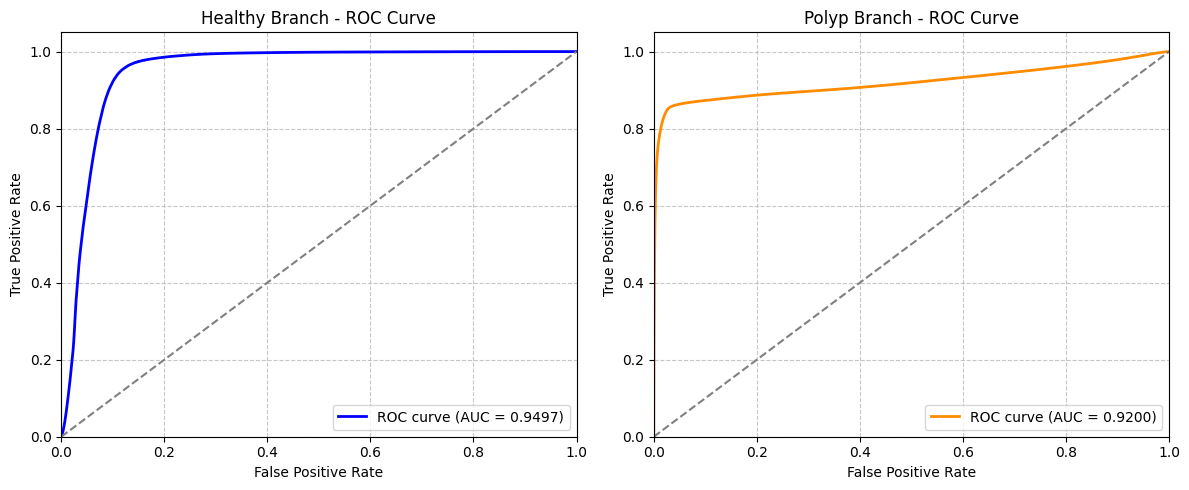

In [22]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from tensorflow.keras.models import load_model

def evaluate_and_plot_roc(model, data_generator, dataset_name="Validation"):
    print(f"--- Calculating ROC & AUC for {dataset_name} Data ---")
    
    all_healthy_true, all_healthy_preds = [], []
    all_polyp_true, all_polyp_preds = [], []
    
    # ডেটা জেনারেটর থেকে ব্যাচ অনুযায়ী প্রেডিকশন এবং প্রবাবিলিটি সংগ্রহ করা
    for i in range(len(data_generator)):
        x_batch, y_batch_dict = data_generator[i]
        
        # Ground Truth (পিক্সেল লেভেল)
        y_true_healthy = y_batch_dict['healthy_output'].flatten()
        y_true_polyp = y_batch_dict['polyp_output'].flatten()
        
        # Model Prediction (Threshold ছাড়া প্রবাবিলিটি বা কন্টিনিউয়াস ভ্যালু)
        preds = model.predict(x_batch, verbose=0)
        y_pred_healthy = preds['healthy_output'].flatten()
        y_pred_polyp = preds['polyp_output'].flatten()
        
        all_healthy_true.append(y_true_healthy)
        all_healthy_preds.append(y_pred_healthy)
        
        all_polyp_true.append(y_true_polyp)
        all_polyp_preds.append(y_pred_polyp)

    # কনক্যাটিনেট করা
    h_true = np.concatenate(all_healthy_true)
    h_pred = np.concatenate(all_healthy_preds)
    
    p_true = np.concatenate(all_polyp_true)
    p_pred = np.concatenate(all_polyp_preds)
    
    # ROC এবং AUC ক্যালকুলেশন
    fpr_h, tpr_h, _ = roc_curve(h_true, h_pred)
    roc_auc_h = auc(fpr_h, tpr_h)
    
    fpr_p, tpr_p, _ = roc_curve(p_true, p_pred)
    roc_auc_p = auc(fpr_p, tpr_p)
    
    print(f"  Healthy Branch AUC : {roc_auc_h:.4f}")
    print(f"  Polyp Branch AUC   : {roc_auc_p:.4f}")
    
    # ---------------------------------------------------------
    # ROC Curve Plotting
    # ---------------------------------------------------------
    plt.figure(figsize=(12, 5))
    
    # Healthy ROC
    plt.subplot(1, 2, 1)
    plt.plot(fpr_h, tpr_h, color='blue', lw=2, label=f'ROC curve (AUC = {roc_auc_h:.4f})')
    plt.plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Healthy Branch - ROC Curve')
    plt.legend(loc="lower right")
    plt.grid(True, linestyle='--', alpha=0.7)
    
    # Polyp ROC
    plt.subplot(1, 2, 2)
    plt.plot(fpr_p, tpr_p, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc_p:.4f})')
    plt.plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Polyp Branch - ROC Curve')
    plt.legend(loc="lower right")
    plt.grid(True, linestyle='--', alpha=0.7)
    
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# এক্সিকিউশন
# ---------------------------------------------------------
if __name__ == "__main__":
    MODEL_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/conference/claude/best_tf_dual_decoder_unet_v1.0.3.keras"
    
    print("Building model architecture...")
    IMG_SIZE = (256, 256)
    model = build_dual_decoder_unet(input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
    
    print("Loading weights into the model...")
    model.load_weights(MODEL_PATH)
    print("Weights loaded successfully!\n")
    
    # ভ্যালিডেশন সেটের জন্য ROC কার্ভ প্লট করা
    evaluate_and_plot_roc(model, val_gen, dataset_name="Validation")

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

def generate_tsne_graph(model, data_generator, num_samples=300):
    print("--- Extracting Features for t-SNE ---")
    
    features_list = []
    labels_list = []
    collected_count = 0
    
    for i in range(len(data_generator)):
        x_batch, y_batch_dict = data_generator[i]
        
        # পলিপ্র উপস্থিতির উপর ভিত্তি করে লেবেল নির্ধারণ (0 = Healthy, 1 = Polyp Present)
        y_polyp = y_batch_dict['polyp_output']
        
        # ব্যাচ থেকে প্রেডিকশন আউটপুট নেওয়া
        batch_features = model.predict(x_batch, verbose=0)
        
        batch_size = x_batch.shape[0]
        for b in range(batch_size):
            if collected_count >= num_samples:
                break
                
            has_polyp = 1 if np.sum(y_polyp[b]) > 10 else 0 
                
            feat = batch_features['polyp_output'][b].flatten()
            
            features_list.append(feat)
            labels_list.append(has_polyp)
            collected_count += 1
            
        if collected_count >= num_samples:
            break

    X = np.array(features_list)
    y = np.array(labels_list)
    
    print(f"Extracted {X.shape[0]} samples with feature dimension {X.shape[1]}. Running t-SNE...")
    
    # t-SNE অ্যাপ্লাই করা (কোনো অপ্রয়োজনীয় আর্গুমেন্ট ছাড়া)
    tsne = TSNE(n_components=2, perplexity=30, random_state=42)
    X_embedded = tsne.fit_transform(X)
    
    # গ্রাফ প্লট করা
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(X_embedded[:, 0], X_embedded[:, 1], c=y, cmap='coolwarm', alpha=0.7, edgecolors='k', s=40)
    
    plt.title('t-SNE Visualization of Model Features')
    plt.xlabel('t-SNE Dimension 1')
    plt.ylabel('t-SNE Dimension 2')
    
    legend1 = plt.legend(*scatter.legend_elements(), title="Classes")
    plt.gca().add_artist(legend1)
    
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

# এক্সিকিউশন
if __name__ == "__main__":
    MODEL_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/conference/claude/best_tf_dual_decoder_unet_v1.0.3.keras"
    
    print("Building model architecture...")
    IMG_SIZE = (256, 256)
    model = build_dual_decoder_unet(input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
    
    print("Loading weights into the model...")
    model.load_weights(MODEL_PATH)
    print("Weights loaded successfully!\n")
    
    generate_tsne_graph(model, val_gen, num_samples=300)

Building model architecture...
Loading weights into the model...
